# EDA Ringkas - NYC Yellow Taxi Januari–Juni 2026
**Analisis Spasial-Temporal dan Prediksi Taxi Demand di NYC: Deteksi Hotspot dan Analisis Pola Permintaan**

| # | EDA | Kenapa menarik / unik | Terkait |
|---|---|---|---|
| 1 | **Pola waktu**: profil jam dan heatmap hari × jam | Langsung menunjukkan jam sibuk; ada uji Mann-Whitney akhir pekan vs hari kerja | Tujuan 1 |
| 2 | **Konsentrasi permintaan antar zona** (Top-K, Pareto, Gini) | Menjawab seberapa timpang permintaan; memuat angka Demand Coverage Top-K | Tujuan 2 & 4, Tabel 1.3 |
| 3 | **Arus asal-tujuan antar borough** | Memperlihatkan arus Manhattan, bandara, dan outer boroughs | Tujuan 4, pemerataan layanan |
| 4 | **Congestion pricing** (`cbd_congestion_fee`) | Fitur khas data 2025–2026 yang tidak ada di dataset TLC lama | Evaluasi kebijakan TLC |
| 5 | **Indeks Potensi Pendapatan** per zona | Zona ramai belum tentu paling menguntungkan | Nilai Bisnis (pickup × rata-rata total_amount) |

## 0. Persiapan

Loading dan Import Library

In [ ]:
import sys, gc, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import scipy
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------------- KONFIGURASI -----------------------------
DATA_DIR     = Path("../data")
FILE_PATTERN = "parquet/{tahun}/yellow_tripdata_{tahun}-{bulan:02d}.parquet"
LOOKUP_CSV   = DATA_DIR / "zone" / "taxi_zone_lookup.csv"
OUT_DIR      = Path("../out/output_eda")
FIG_DIR      = OUT_DIR / "figures"

TAHUN        = 2026
BULAN        = [1, 2, 3, 4, 5, 6]
# False = lebih cepat & hemat RAM
CEK_DUPLIKAT = True      
SEED         = 42
ALPHA        = 0.05

# Hari libur federal AS 2026 (sunting bila perlu)
HARI_LIBUR = {"2026-01-01": "New Year's Day", 
              "2026-01-19": "MLK Day", 
              "2026-02-16": "Presidents' Day",
              "2026-05-25": "Memorial Day", 
              "2026-06-19": "Juneteenth"}
# -----------------------------------------------------------------------

np.random.seed(SEED)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

NAMA_HARI  = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
NAMA_BULAN = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun"}

def simpan(nama):
    plt.savefig(FIG_DIR / f"{nama}.png", dpi=150, bbox_inches="tight")

def ribuan(x, pos=None):
    return f"{x:,.0f}"


# Cek Versi
# print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
#       "| scipy", scipy.__version__, "| seaborn", sns.__version__, "| seed", SEED) #type :ignore

## Prasyarat: Pemuatan dan Pembersihan Ringan

Data dimuat **satu bulan sekali**. Baris tidak valid dibuang memakai aturan pembersihan yang direncanakan di laporan,
lalu dari baris valid dibuat dua agregat yang menjadi bahan kelima EDA: **pickup per zona-jam** dan **matriks asal-tujuan**.

In [4]:
KOLOM_WAJIB = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID",
               "trip_distance", "fare_amount", "total_amount"]

ATURAN_BUANG = ["Pickup di luar bulan berkas", "Durasi <= 0 (dropoff <= pickup)", "fare_amount negatif",
                "trip_distance > 100 mil", "fare_amount > $1000", "PULocationID di luar 1-263"]


def proses_bulan(bulan):
    path = DATA_DIR / FILE_PATTERN.format(tahun=TAHUN, bulan=bulan)
    df = pd.read_parquet(path)
    df.columns = ["Airport_fee" if c.lower() == "airport_fee" else c for c in df.columns]
    kurang = [c for c in KOLOM_WAJIB if c not in df.columns]
    if kurang:
        raise KeyError(f"Kolom wajib tidak ada di {path.name}: {kurang}")
    if "cbd_congestion_fee" not in df.columns:
        print(f"   [!] cbd_congestion_fee tidak ada di bulan {bulan:02d}; diisi 0")
        df["cbd_congestion_fee"] = 0.0

    n = len(df)
    miss = df.isna().sum()
    dup = int(df.duplicated().sum()) if CEK_DUPLIKAT else np.nan

    pu_t, do_t = df["tpep_pickup_datetime"], df["tpep_dropoff_datetime"]
    awal = pd.Timestamp(TAHUN, bulan, 1)
    akhir = awal + pd.offsets.MonthBegin(1)
    flag = pd.DataFrame({
        ATURAN_BUANG[0]: ~((pu_t >= awal) & (pu_t < akhir)),
        ATURAN_BUANG[1]: do_t <= pu_t,
        ATURAN_BUANG[2]: df["fare_amount"] < 0,
        ATURAN_BUANG[3]: df["trip_distance"] > 100,
        ATURAN_BUANG[4]: df["fare_amount"] > 1000,
        ATURAN_BUANG[5]: ~df["PULocationID"].between(1, 263),
    })
    valid = ~flag.any(axis=1)

    v = df.loc[valid, ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "total_amount",
                       "cbd_congestion_fee"]].copy()
    del df
    v["jam"] = v["tpep_pickup_datetime"].dt.floor("60min")
    v["cbd"] = v["cbd_congestion_fee"].fillna(0) > 0

    zh = (v.groupby(["PULocationID", "jam"])
            .agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"), cbd_trips=("cbd", "sum"))
            .reset_index())
    od = (v.groupby(["PULocationID", "DOLocationID"])
            .agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"), cbd_trips=("cbd", "sum"))
            .reset_index())
    ringkas = dict(bulan=bulan, baris_mentah=n, baris_valid=int(valid.sum()), duplikat=dup,
                   pct_cbd=v["cbd"].mean() * 100)
    del v
    gc.collect()
    return dict(ringkas=ringkas, miss=miss, flag_n=flag.sum(), zh=zh, od=od)


hasil = {}
for b in BULAN:
    print(f"Memproses bulan {b:02d} ...", end=" ", flush=True)
    hasil[b] = proses_bulan(b)
    r = hasil[b]["ringkas"]
    print(f"{r['baris_mentah']:,} baris -> {r['baris_valid']:,} valid")

ringkas  = pd.DataFrame([h["ringkas"] for h in hasil.values()]).set_index("bulan")
miss_all = pd.concat([h["miss"] for h in hasil.values()], axis=1).sum(axis=1)
flag_df  = pd.DataFrame({b: h["flag_n"] for b, h in hasil.items()}).T
zh_all   = pd.concat([h["zh"] for h in hasil.values()], ignore_index=True)
zh_all["jam"] = pd.to_datetime(zh_all["jam"]).astype("datetime64[ns]")
od_all   = (pd.concat([h["od"] for h in hasil.values()], ignore_index=True)
              .groupby(["PULocationID", "DOLocationID"], as_index=False).sum())
N_MENTAH = int(ringkas["baris_mentah"].sum())
N_VALID  = int(ringkas["baris_valid"].sum())
print(f"\nTotal: {N_MENTAH:,} baris mentah | {N_VALID:,} valid ({N_VALID / N_MENTAH:.2%})")

# ---------- ringkasan kualitas data ----------
tot = flag_df.sum()
q = pd.DataFrame({"jumlah_baris": tot, "persen": tot / N_MENTAH * 100})
display(q.style.format({"jumlah_baris": "{:,.0f}", "persen": "{:.3f}%"}))
mv = pd.DataFrame({"jumlah_kosong": miss_all.astype(int), "persen": miss_all / N_MENTAH * 100})
mv = mv[mv["jumlah_kosong"] > 0].sort_values("persen", ascending=False)
print("Kolom dengan missing value:")
display(mv.style.format({"jumlah_kosong": "{:,.0f}", "persen": "{:.2f}%"}))
if CEK_DUPLIKAT:
    print(f"Baris duplikat: {int(ringkas['duplikat'].sum()):,}")

Memproses bulan 01 ... 3,724,889 baris -> 3,634,444 valid
Memproses bulan 02 ... 3,399,866 baris -> 3,327,475 valid
Memproses bulan 03 ... 3,952,451 baris -> 3,876,309 valid
Memproses bulan 04 ... 3,831,240 baris -> 3,761,346 valid
Memproses bulan 05 ... 4,090,836 baris -> 4,018,027 valid
Memproses bulan 06 ... 3,837,248 baris -> 3,767,239 valid

Total: 22,836,530 baris mentah | 22,384,840 valid (98.02%)


,jumlah_baris,persen
Pickup di luar bulan berkas,85,0.000%
Durasi <= 0 (dropoff <= pickup),"286,182",1.253%
fare_amount negatif,"129,115",0.565%
trip_distance > 100 mil,916,0.004%
fare_amount > $1000,25,0.000%
PULocationID di luar 1-263,"36,288",0.159%


Kolom dengan missing value:


,jumlah_kosong,persen
passenger_count,"5,825,780",25.51%
RatecodeID,"5,825,780",25.51%
store_and_fwd_flag,"5,825,780",25.51%
congestion_surcharge,"5,825,780",25.51%
Airport_fee,"5,825,780",25.51%
request_source,"2,824,068",12.37%


Baris duplikat: 0


In [ ]:
# ---------- Taxi Zone Lookup ----------
if LOOKUP_CSV.exists():
    lookup = pd.read_csv(LOOKUP_CSV)
else:
    print(f"[!] {LOOKUP_CSV} tidak ditemukan -> nama zona & borough memakai label generik "
          "(EDA 3 dan 4 per borough jadi kurang bermakna).")
    lookup = pd.DataFrame({"LocationID": sorted(zh_all["PULocationID"].unique())})
    lookup["Borough"] = "Tidak diketahui"
    lookup["Zone"] = "Zona " + lookup["LocationID"].astype(str)

lookup["Borough"] = lookup["Borough"].fillna("Tidak diketahui")
lookup["Zone"] = lookup["Zone"].fillna("?")
lookup["label"] = lookup["Zone"] + " (" + lookup["LocationID"].astype(str) + ")"
b_map   = lookup.set_index("LocationID")["Borough"]
lbl_map = lookup.set_index("LocationID")["label"]

def nama_zona(z):
    return lbl_map.get(z, f"Zona {z}")

# ---------- tabel zona (dipakai EDA 2, 4, 5) ----------
# diisi di EDA 1
N_HARI_RENTANG = None  
zone_tot = (zh_all.groupby("PULocationID")
                  .agg(trips=("trips", "sum"), revenue=("revenue", "sum"), cbd_trips=("cbd_trips", "sum"))
                  .reset_index().rename(columns={"PULocationID": "LocationID"}))
zone_tot = zone_tot.merge(lookup[["LocationID", "Borough", "Zone", "label"]], on="LocationID", how="left")
zone_tot["Borough"] = zone_tot["Borough"].fillna("Tidak diketahui")
zone_tot["Zone"] = zone_tot["Zone"].fillna("?")
zone_tot["label"] = zone_tot["label"].fillna(zone_tot["LocationID"].map(lambda z: f"Zona {z}"))
zone_tot["share"] = zone_tot["trips"] / zone_tot["trips"].sum() * 100
zone_tot["rata_total"] = zone_tot["revenue"] / zone_tot["trips"]
zone_tot = zone_tot.sort_values("trips", ascending=False).reset_index(drop=True)

## EDA 1 - Pola Waktu: Profil Jam dan Heatmap Hari × Jam

**Pertanyaan:** kapan permintaan taksi memuncak, dan apakah akhir pekan berbeda dari hari kerja?
Unit analisis adalah pickup per jam seluruh kota. Satu jam hilang karena *Daylight Saving Time* (8 Maret 2026); jam itu **bukan** permintaan nol sehingga dikeluarkan.

Jam dianalisis: 4,343 | jam dikeluarkan (DST): ['2026-03-08 02:00:00']


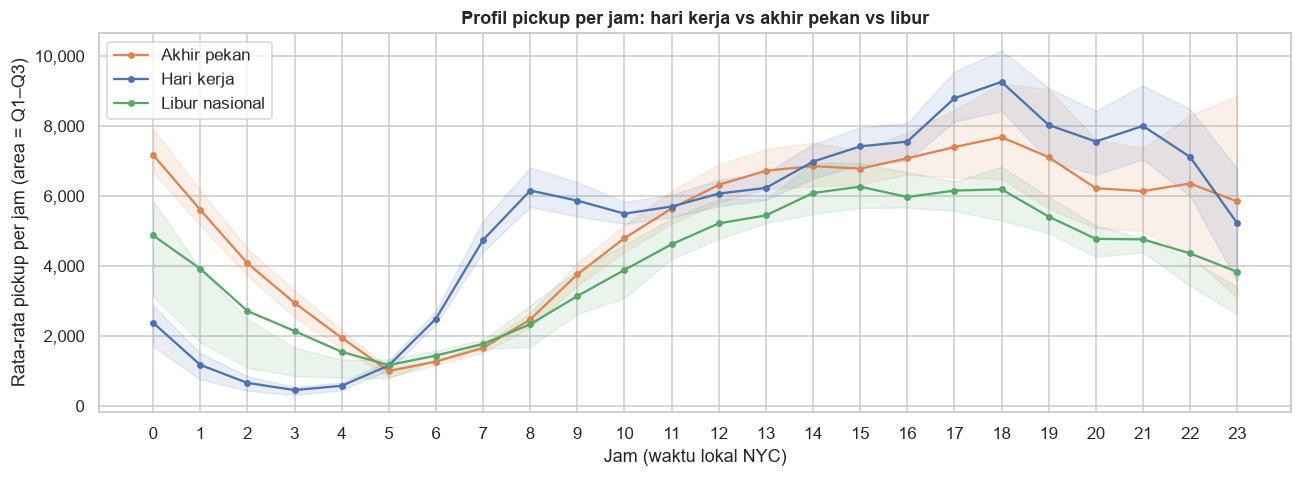

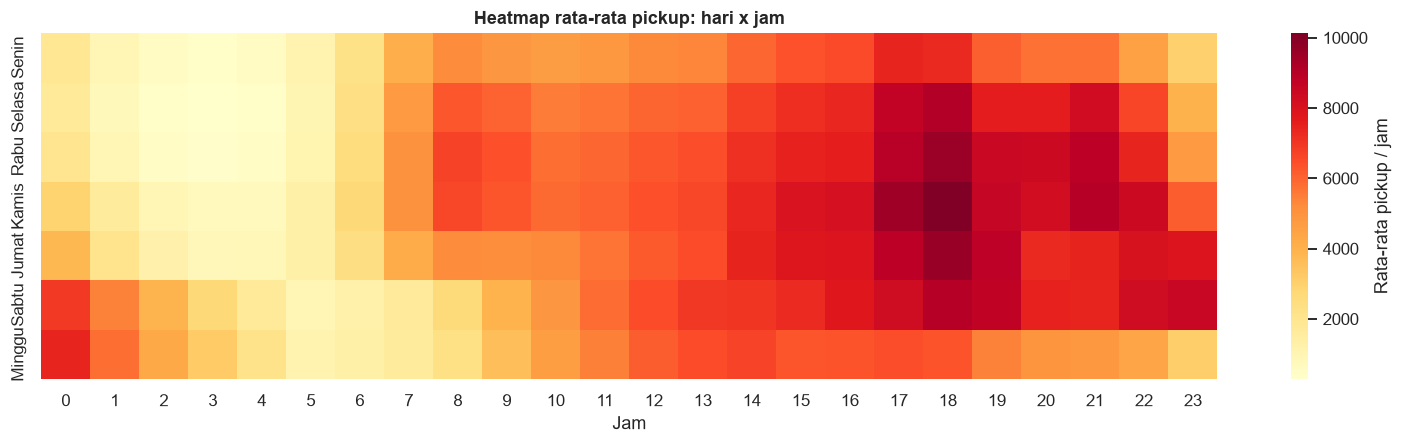

Jam puncak : 18:00 (8,724 pickup/jam)
Jam tersepi: 04:00 (995 pickup/jam)
Hari tersibuk: Kamis | hari tersepi: Senin

Mann-Whitney U (pickup/hari, akhir pekan n=52 vs hari kerja n=124): U = 2,971, p = 4.13e-01, Cliff's delta = -0.08
Kesimpulan pada alpha 5%: tidak ada perbedaan signifikan (gagal tolak H0) | delta > 0 = akhir pekan lebih ramai, delta < 0 = hari kerja lebih ramai


In [6]:
# ---------- Bangun deret waktu per jam ----------
awal_data  = pd.Timestamp(TAHUN, BULAN[0], 1)
akhir_data = pd.Timestamp(TAHUN, BULAN[-1], 1) + pd.offsets.MonthBegin(1)
rentang = pd.date_range(awal_data, akhir_data, freq="60min", inclusive="left").astype("datetime64[ns]")
ts = zh_all.groupby("jam")["trips"].sum().reindex(rentang, fill_value=0)

tsd = ts.rename("trips").to_frame()
tsd["tanggal"]  = tsd.index.normalize()
tsd["jam_hari"] = tsd.index.hour
tsd["hari"]     = tsd.index.dayofweek
tsd["akhir_pekan"] = tsd["hari"] >= 5
libur_set = pd.to_datetime(list(HARI_LIBUR)).astype("datetime64[ns]")
tsd["libur"] = tsd["tanggal"].isin(libur_set)
tsd["tipe_hari"] = np.where(tsd["libur"], "Libur nasional", np.where(tsd["akhir_pekan"], "Akhir pekan", "Hari kerja"))

# jam yang tidak ada di waktu lokal (DST): minggu ke-2 Maret pukul 02:00
hilang_dst = []
if 3 in BULAN:
    d = pd.Timestamp(TAHUN, 3, 1)
    hilang_dst = [d + pd.Timedelta(days=(6 - d.dayofweek) % 7 + 7, hours=2)]
tsd_v = tsd.drop(index=[h for h in hilang_dst if h in tsd.index])
N_JAM, N_HARI = len(tsd_v), tsd_v["tanggal"].nunique()
print(f"Jam dianalisis: {N_JAM:,} | jam dikeluarkan (DST): {[str(h) for h in hilang_dst]}")

harian = tsd_v.groupby("tanggal").agg(trips=("trips", "sum"), akhir_pekan=("akhir_pekan", "first"),
                                      libur=("libur", "first"))

# ---------- Profil jam: hari kerja vs akhir pekan vs libur ----------
prof = (tsd_v.groupby(["tipe_hari", "jam_hari"])["trips"]
             .agg(rata="mean", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)).reset_index())
warna = {"Hari kerja": "#4C72B0", "Akhir pekan": "#DD8452", "Libur nasional": "#55A868"}
fig, ax = plt.subplots(figsize=(12, 4.5))
for tipe, g in prof.groupby("tipe_hari"):
    ax.plot(g["jam_hari"], g["rata"], marker="o", ms=3.5, color=warna[tipe], label=tipe)
    ax.fill_between(g["jam_hari"], g["q1"], g["q3"], color=warna[tipe], alpha=.12)
ax.set_xticks(range(24)); ax.yaxis.set_major_formatter(mtick.FuncFormatter(ribuan))
ax.set_xlabel("Jam (waktu lokal NYC)"); ax.set_ylabel("Rata-rata pickup per jam (area = Q1–Q3)")
ax.set_title("Profil pickup per jam: hari kerja vs akhir pekan vs libur"); ax.legend()
plt.tight_layout(); simpan("eda1_profil_jam"); plt.show()

# ---------- Heatmap hari x jam ----------
pv = tsd_v.pivot_table(index="hari", columns="jam_hari", values="trips", aggfunc="mean")
pv.index = [NAMA_HARI[i] for i in pv.index]
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(pv, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Rata-rata pickup / jam"})
ax.set_xlabel("Jam"); ax.set_ylabel(""); ax.set_title("Heatmap rata-rata pickup: hari x jam")
plt.tight_layout(); simpan("eda1_heatmap_hari_jam"); plt.show()

rata_jam = tsd_v.groupby("jam_hari")["trips"].mean()
rata_hari = tsd_v.groupby("hari")["trips"].mean()
print(f"Jam puncak : {rata_jam.idxmax():02d}:00 ({rata_jam.max():,.0f} pickup/jam)")
print(f"Jam tersepi: {rata_jam.idxmin():02d}:00 ({rata_jam.min():,.0f} pickup/jam)")
print(f"Hari tersibuk: {NAMA_HARI[int(rata_hari.idxmax())]} | hari tersepi: {NAMA_HARI[int(rata_hari.idxmin())]}")

# ---------- Uji Mann-Whitney U: akhir pekan vs hari kerja (pickup per hari, tanpa libur) ----------
d_nl = harian[~harian["libur"]]
a, b = d_nl.loc[d_nl["akhir_pekan"], "trips"], d_nl.loc[~d_nl["akhir_pekan"], "trips"]
u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
cliff = 2 * u / (len(a) * len(b)) - 1
print(f"\nMann-Whitney U (pickup/hari, akhir pekan n={len(a)} vs hari kerja n={len(b)}): "
      f"U = {u:,.0f}, p = {p:.2e}, Cliff's delta = {cliff:.2f}")
print("Kesimpulan pada alpha 5%:", "ada perbedaan signifikan (tolak H0)" if p < ALPHA else "tidak ada perbedaan signifikan (gagal tolak H0)",
      "| delta > 0 = akhir pekan lebih ramai, delta < 0 = hari kerja lebih ramai")

> **Catatan interpretasi (isi setelah menjalankan):** jam puncak dan sepi, apakah pola akhir pekan bergeser (mis. puncak malam lebih lambat),
> hasil uji Mann-Whitney beserta arah efeknya, dan jam sibuk mana yang paling layak jadi fokus alokasi armada.

## EDA 2 - Konsentrasi Permintaan Antar Zona (Top-K, Pareto, Gini)

**Pertanyaan:** seberapa terkonsentrasi permintaan di segelintir zona? Hasil ini berhubungan langsung dengan metrik *Demand Coverage Top-K* di Tabel 1.3
dan memberi gambaran awal tentang hotspot.

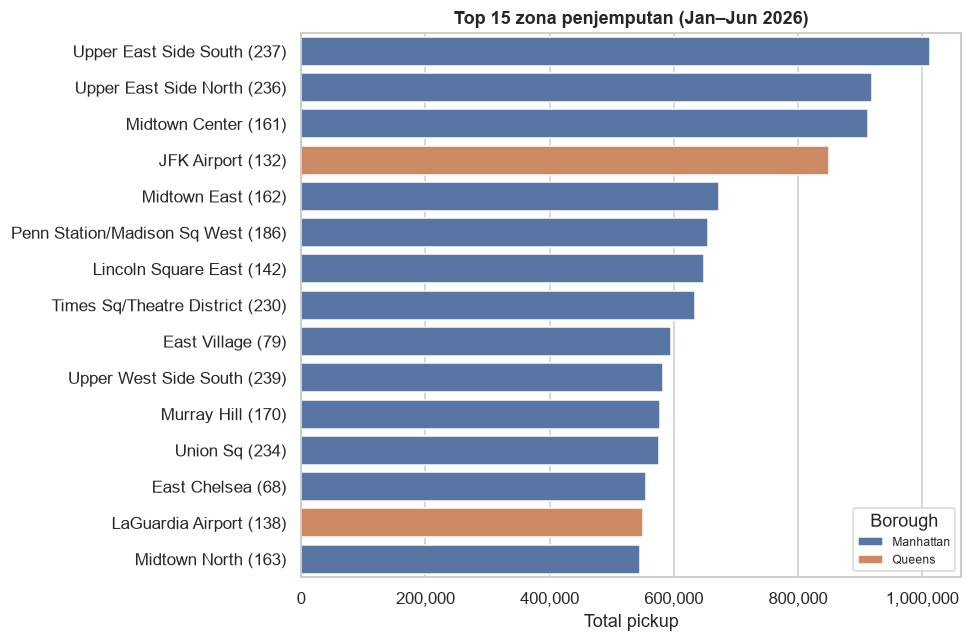

,K,% zona,% pickup tertangkap,lift vs rata-rata
0,5,1.9%,19.5%,10.3x
1,10,3.8%,33.4%,8.8x
2,20,7.6%,56.6%,7.4x
3,50,19.0%,89.7%,4.7x
4,100,38.0%,97.3%,2.6x


Koefisien Gini = 0.815 (0 = merata, 1 = semua permintaan di satu zona)


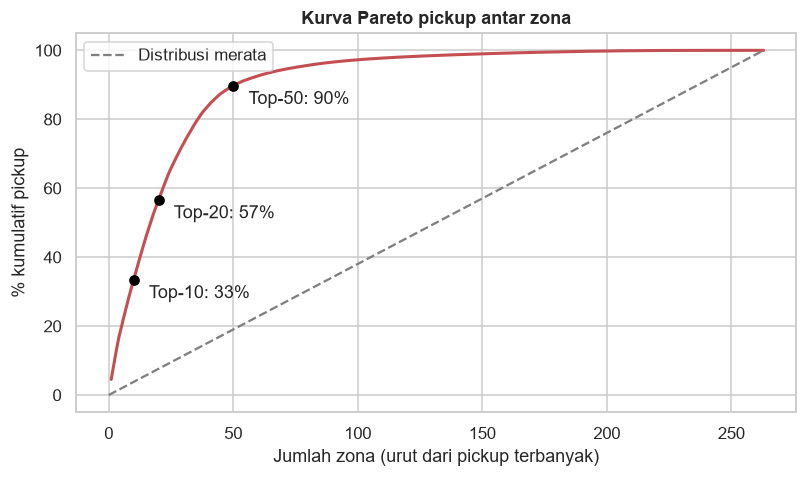


Sel zona-jam bernilai nol: 39.9% dari 1,142,209 sel (263 zona x 4,343 jam)
-> alasan memakai WAPE / sMAPE / MASE, bukan MAPE yang bermasalah saat nilai aktual = 0.


In [7]:
# ---------- Top 15 zona pickup ----------
t15 = zone_tot.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=t15["trips"], y=t15["label"], hue=t15["Borough"], dodge=False, ax=ax)
ax.set_title("Top 15 zona penjemputan (Jan–Jun 2026)"); ax.set_ylabel(""); ax.set_xlabel("Total pickup")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(ribuan)); ax.legend(title="Borough", fontsize=8)
plt.tight_layout(); simpan("eda2_top15_zona"); plt.show()

# ---------- Demand Coverage Top-K ----------
semua_zona = np.arange(1, 264)
zt_full = zone_tot.set_index("LocationID")["trips"].reindex(semua_zona, fill_value=0).sort_values(ascending=False)
kum = zt_full.cumsum() / zt_full.sum() * 100

cov = pd.DataFrame({"K": [5, 10, 20, 50, 100]})
cov["% zona"] = cov["K"] / 263 * 100
cov["% pickup tertangkap"] = [kum.iloc[k - 1] for k in cov["K"]]
cov["lift vs rata-rata"] = cov["% pickup tertangkap"] / cov["% zona"]
display(cov.style.format({"% zona": "{:.1f}%", "% pickup tertangkap": "{:.1f}%", "lift vs rata-rata": "{:.1f}x"}))

xs = np.sort(zt_full.values.astype(float))
n = len(xs)
GINI = (2 * np.sum(np.arange(1, n + 1) * xs) / (n * xs.sum())) - (n + 1) / n
print(f"Koefisien Gini = {GINI:.3f} (0 = merata, 1 = semua permintaan di satu zona)")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(np.arange(1, n + 1), kum.values, color="#C44E52", lw=2)
ax.plot([0, n], [0, 100], color="grey", ls="--", label="Distribusi merata")
for k in (10, 20, 50):
    ax.scatter([k], [kum.iloc[k - 1]], color="black", zorder=5)
    ax.annotate(f"Top-{k}: {kum.iloc[k - 1]:.0f}%", (k, kum.iloc[k - 1]), textcoords="offset points", xytext=(10, -12))
ax.set_xlabel("Jumlah zona (urut dari pickup terbanyak)"); ax.set_ylabel("% kumulatif pickup")
ax.set_title("Kurva Pareto pickup antar zona"); ax.legend()
plt.tight_layout(); simpan("eda2_pareto"); plt.show()

# ---------- Sparsity: berapa banyak sel zona-jam bernilai nol? ----------
sel_total = 263 * N_JAM
PCT_NOL = (1 - len(zh_all) / sel_total) * 100
print(f"\nSel zona-jam bernilai nol: {PCT_NOL:.1f}% dari {sel_total:,} sel (263 zona x {N_JAM:,} jam)")
print("-> alasan memakai WAPE / sMAPE / MASE, bukan MAPE yang bermasalah saat nilai aktual = 0.")

> **Catatan interpretasi:** zona paling dominan, berapa persen pickup yang ditangkap Top-10/Top-20 zona, nilai Gini,
> dan implikasi sparsity bagi pemilihan metrik serta pemodelan (mis. model terpisah untuk zona volume tinggi).

## EDA 3 - Arus Asal-Tujuan Antar Borough

**Pertanyaan:** ke mana penumpang dari tiap borough pergi? Apakah layanan taksi kuning hampir seluruhnya berputar di Manhattan?
Hasilnya relevan untuk isu pemerataan layanan di outer boroughs.

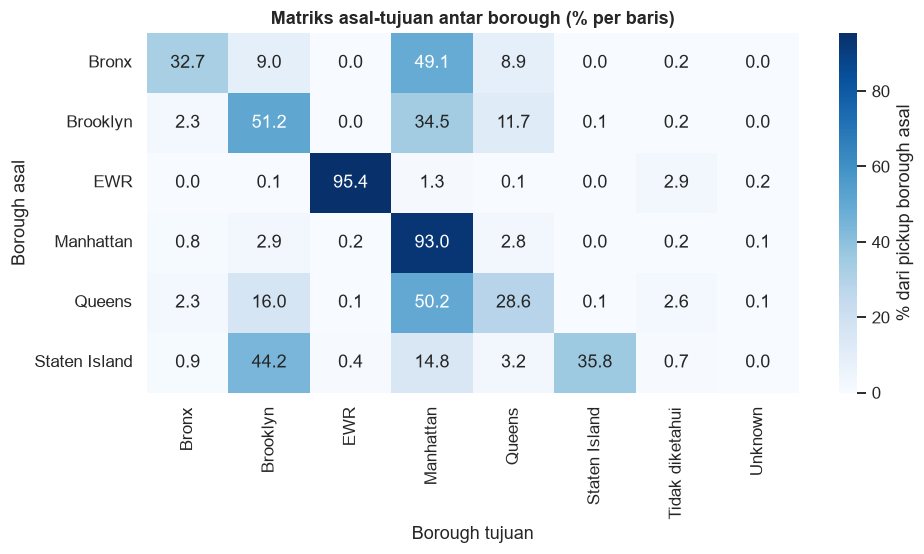

Perjalanan di dalam zona yang sama (PU = DO): 4.4%
Perjalanan yang asal dan tujuannya satu borough: 85.2%

10 rute asal-tujuan teratas:


,Rute,trips,% total
46082,Upper East Side South (237) -> Upper East Side North (236),"149,985",0.67%
45832,Upper East Side North (236) -> Upper East Side South (237),"128,280",0.57%
46083,Upper East Side South (237) -> Upper East Side South (237),"101,549",0.45%
45831,Upper East Side North (236) -> Upper East Side North (236),"98,587",0.44%
30869,Midtown Center (161) -> Upper East Side South (237),"66,453",0.30%
46011,Upper East Side South (237) -> Midtown Center (161),"61,164",0.27%
30868,Midtown Center (161) -> Upper East Side North (236),"54,746",0.24%
46567,Upper West Side South (239) -> Upper West Side North (238),"51,168",0.23%
27007,Lincoln Square East (142) -> Upper West Side South (239),"51,089",0.23%
46012,Upper East Side South (237) -> Midtown East (162),"50,051",0.22%


In [8]:
od_b = od_all.assign(PU_b=od_all["PULocationID"].map(b_map).fillna("Tidak diketahui"),
                     DO_b=od_all["DOLocationID"].map(b_map).fillna("Tidak diketahui"))
mat = od_b.pivot_table(index="PU_b", columns="DO_b", values="trips", aggfunc="sum", fill_value=0)
mat_pct = mat.div(mat.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.heatmap(mat_pct, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "% dari pickup borough asal"})
ax.set_xlabel("Borough tujuan"); ax.set_ylabel("Borough asal"); ax.set_title("Matriks asal-tujuan antar borough (% per baris)")
plt.tight_layout(); simpan("eda3_od_borough"); plt.show()

intra = od_all.loc[od_all["PULocationID"] == od_all["DOLocationID"], "trips"].sum() / od_all["trips"].sum() * 100
dalam_borough = np.trace(mat.reindex(index=mat.index, columns=mat.index, fill_value=0).values) / mat.values.sum() * 100
print(f"Perjalanan di dalam zona yang sama (PU = DO): {intra:.1f}%")
print(f"Perjalanan yang asal dan tujuannya satu borough: {dalam_borough:.1f}%")

top_od = od_all.nlargest(10, "trips").copy()
top_od["Rute"] = [f"{nama_zona(a)} -> {nama_zona(b)}" for a, b in zip(top_od["PULocationID"], top_od["DOLocationID"])]
top_od["% total"] = top_od["trips"] / od_all["trips"].sum() * 100
print("\n10 rute asal-tujuan teratas:")
display(top_od[["Rute", "trips", "% total"]].style.format({"trips": "{:,.0f}", "% total": "{:.2f}%"}))

> **Catatan interpretasi:** borough mana yang paling "mandiri" (tujuan sebagian besar di borough sendiri), seberapa besar arus ke Manhattan,
> peran bandara (JFK/LGA) pada rute teratas, dan apa artinya bagi alokasi armada di luar Manhattan.

## EDA 4 - Jejak Congestion Pricing (`cbd_congestion_fee`)

**Pertanyaan:** berapa persen perjalanan yang dikenai biaya Congestion Relief Zone, kapan, dan antar borough mana?
Kolom ini hanya ada pada data sejak 2025, sehingga menjadi pembeda utama dataset ini dari data taksi NYC lama.

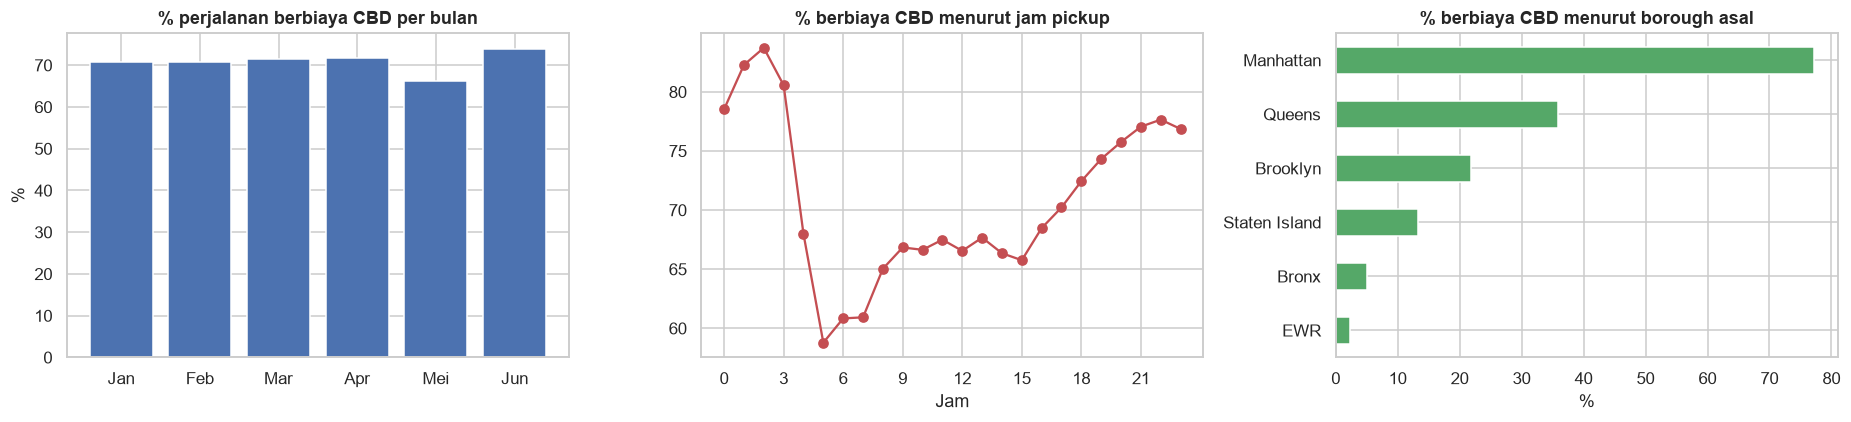

% perjalanan berbiaya CBD menurut borough TUJUAN:


,% berbiaya CBD
DO_b,
EWR,88.6
Manhattan,76.3
Unknown,71.7
Staten Island,40.8
Tidak diketahui,38.0
Brooklyn,35.8
Queens,34.8
Bronx,17.0


Zona asal dengan persentase perjalanan berbiaya CBD tertinggi (min. 5.000 pickup):


,label,Borough,trips,pct_cbd
5,Penn Station/Madison Sq West (186),Manhattan,"654,384",98.8%
4,Midtown East (162),Manhattan,"673,019",98.7%
24,Sutton Place/Turtle Bay North (229),Manhattan,"355,935",98.6%
14,Midtown North (163),Manhattan,"546,061",98.6%
2,Midtown Center (161),Manhattan,"913,077",98.3%
7,Times Sq/Theatre District (230),Manhattan,"633,558",98.1%
16,Clinton East (48),Manhattan,"503,121",98.0%
11,Union Sq (234),Manhattan,"575,532",98.0%
28,Greenwich Village North (113),Manhattan,"311,825",97.9%
27,Greenwich Village South (114),Manhattan,"321,992",97.9%


In [9]:
zh_all["jam_hari"] = zh_all["jam"].dt.hour
cbd_jam = zh_all.groupby("jam_hari")[["cbd_trips", "trips"]].sum()
cbd_jam["pct"] = cbd_jam["cbd_trips"] / cbd_jam["trips"] * 100
cbd_pu = zone_tot.groupby("Borough")[["cbd_trips", "trips"]].sum()
cbd_pu["pct"] = cbd_pu["cbd_trips"] / cbd_pu["trips"] * 100
cbd_do = od_b.groupby("DO_b")[["cbd_trips", "trips"]].sum()
cbd_do["pct"] = cbd_do["cbd_trips"] / cbd_do["trips"] * 100

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].bar([NAMA_BULAN[b] for b in ringkas.index], ringkas["pct_cbd"], color="#4C72B0")
ax[0].set_title("% perjalanan berbiaya CBD per bulan"); ax[0].set_ylabel("%")
ax[1].plot(cbd_jam.index, cbd_jam["pct"], marker="o", color="#C44E52")
ax[1].set_title("% berbiaya CBD menurut jam pickup"); ax[1].set_xlabel("Jam"); ax[1].set_xticks(range(0, 24, 3))
cbd_pu["pct"].sort_values().plot(kind="barh", ax=ax[2], color="#55A868")
ax[2].set_title("% berbiaya CBD menurut borough asal"); ax[2].set_xlabel("%"); ax[2].set_ylabel("")
plt.tight_layout(); simpan("eda4_cbd_fee"); plt.show()

print("% perjalanan berbiaya CBD menurut borough TUJUAN:")
display(cbd_do["pct"].sort_values(ascending=False).round(1).to_frame("% berbiaya CBD"))

print("Zona asal dengan persentase perjalanan berbiaya CBD tertinggi (min. 5.000 pickup):")
cbd_zona = zone_tot[zone_tot["trips"] >= 5000].assign(pct_cbd=lambda x: x["cbd_trips"] / x["trips"] * 100)
display(cbd_zona.nlargest(10, "pct_cbd")[["label", "Borough", "trips", "pct_cbd"]]
        .style.format({"trips": "{:,.0f}", "pct_cbd": "{:.1f}%"}))

> **Catatan interpretasi:** apakah porsi perjalanan berbiaya CBD stabil antarbulan (pola "normal baru"), pada jam berapa paling tinggi,
> dan apakah biaya terutama muncul pada perjalanan yang berasal dari/menuju Manhattan. Data ini tidak bisa membandingkan sebelum vs sesudah kebijakan.

## EDA 5 - Indeks Potensi Pendapatan per Zona

**Pertanyaan:** apakah zona dengan pickup terbanyak juga yang paling menguntungkan?
Indeks Potensi Pendapatan didefinisikan seperti di laporan: *jumlah pickup × rata-rata `total_amount`* (= total pendapatan zona).

Korelasi peringkat (Spearman) pickup vs pendapatan: rho = 0.995 (p = 6.5e-256)


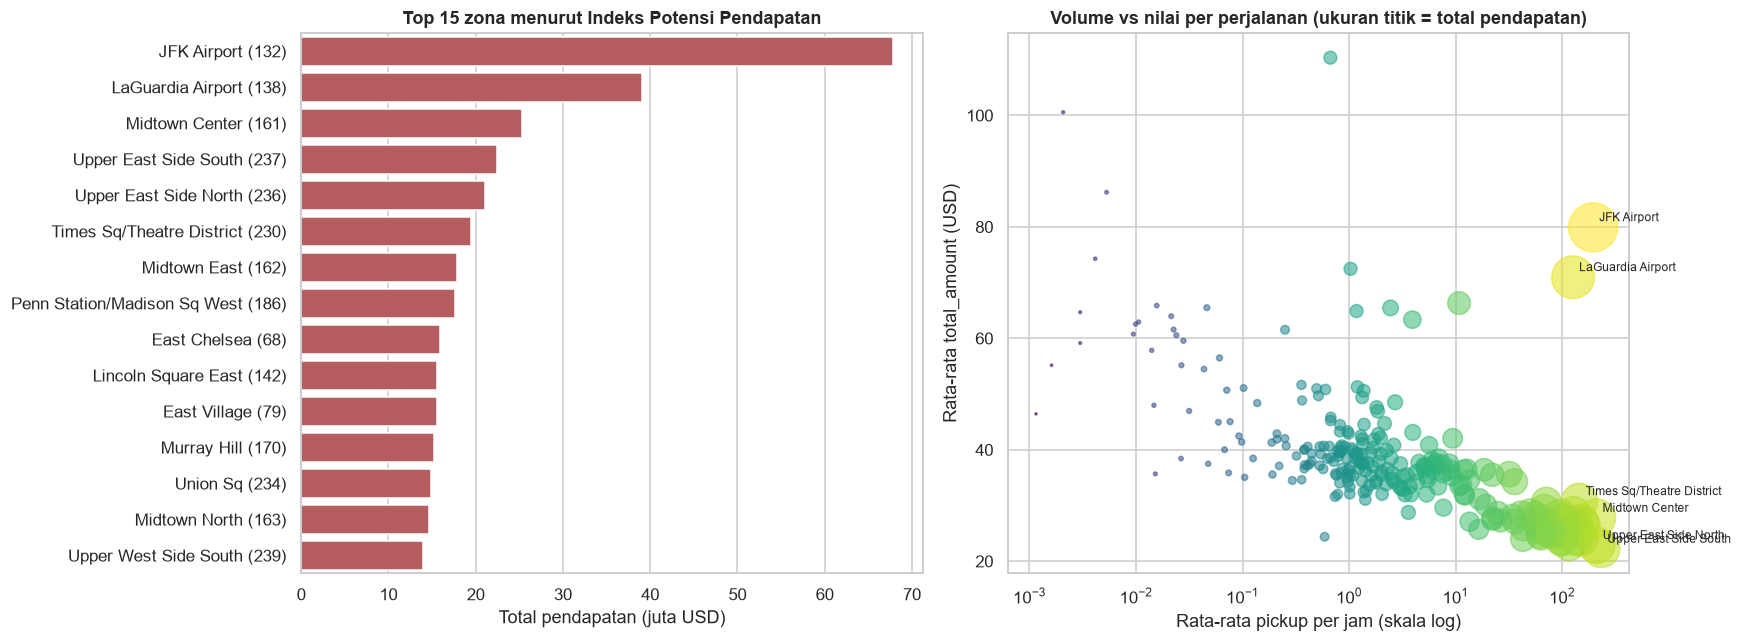

Zona dengan rata-rata biaya per perjalanan tertinggi (min. 1.000 pickup):


,label,Borough,trips,rata_total
190,Newark Airport (1),EWR,"2,902",$110.35
3,JFK Airport (132),Queens,"849,279",$79.91
157,Flushing Meadows-Corona Park (93),Queens,"4,487",$72.46
13,LaGuardia Airport (138),Queens,"550,742",$70.95
62,East Elmhurst (70),Queens,"46,917",$66.32
107,Baisley Park (10),Queens,"10,654",$65.45
151,Springfield Gardens South (219),Queens,"5,108",$64.89
90,South Ozone Park (216),Queens,"17,079",$63.35
217,Randalls Island (194),Manhattan,"1,090",$61.53
213,Glen Oaks (101),Queens,"1,553",$51.63


Zona 'bernilai lebih besar dari ramainya' (peringkat pendapatan jauh lebih baik dari peringkat pickup):


,label,Borough,rank_pickup,rank_revenue,rata_total
190,Newark Airport (1),EWR,191,120,$110.35
157,Flushing Meadows-Corona Park (93),Queens,158,119,$72.46
151,Springfield Gardens South (219),Queens,152,117,$64.89
90,South Ozone Park (216),Queens,91,72,$63.35
107,Baisley Park (10),Queens,108,90,$65.45
149,Kew Gardens (134),Queens,150,133,$51.28
62,East Elmhurst (70),Queens,63,48,$66.32
140,Hammels/Arverne (117),Queens,141,127,$49.38


In [10]:
zone_tot["rank_pickup"] = zone_tot["trips"].rank(ascending=False)
zone_tot["rank_revenue"] = zone_tot["revenue"].rank(ascending=False)
rho, p_rho = stats.spearmanr(zone_tot["rank_pickup"], zone_tot["rank_revenue"])
print(f"Korelasi peringkat (Spearman) pickup vs pendapatan: rho = {rho:.3f} (p = {p_rho:.1e})")

zone_tot["pickup_per_jam"] = zone_tot["trips"] / N_JAM
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
r15 = zone_tot.nlargest(15, "revenue")
sns.barplot(x=r15["revenue"] / 1e6, y=r15["label"], ax=ax[0], color="#C44E52")
ax[0].set_title("Top 15 zona menurut Indeks Potensi Pendapatan"); ax[0].set_xlabel("Total pendapatan (juta USD)"); ax[0].set_ylabel("")

ax[1].scatter(zone_tot["pickup_per_jam"], zone_tot["rata_total"], s=np.sqrt(zone_tot["revenue"]) / 8, alpha=.55,
              c=np.log10(zone_tot["revenue"].clip(lower=1)), cmap="viridis")
ax[1].set_xscale("log"); ax[1].set_xlabel("Rata-rata pickup per jam (skala log)"); ax[1].set_ylabel("Rata-rata total_amount (USD)")
ax[1].set_title("Volume vs nilai per perjalanan (ukuran titik = total pendapatan)")
for _, r in zone_tot.nlargest(6, "revenue").iterrows():
    ax[1].annotate(r["Zone"], (r["pickup_per_jam"], r["rata_total"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.tight_layout(); simpan("eda5_indeks_pendapatan"); plt.show()

print("Zona dengan rata-rata biaya per perjalanan tertinggi (min. 1.000 pickup):")
display(zone_tot[zone_tot["trips"] >= 1000].nlargest(10, "rata_total")[["label", "Borough", "trips", "rata_total"]]
        .style.format({"trips": "{:,.0f}", "rata_total": "${:.2f}"}))

# zona yang peringkat pendapatannya jauh lebih baik daripada peringkat volumenya
zone_tot["selisih_rank"] = zone_tot["rank_pickup"] - zone_tot["rank_revenue"]
print("Zona 'bernilai lebih besar dari ramainya' (peringkat pendapatan jauh lebih baik dari peringkat pickup):")
display(zone_tot[zone_tot["trips"] >= 1000].nlargest(8, "selisih_rank")[["label", "Borough", "rank_pickup", "rank_revenue", "rata_total"]]
        .style.format({"rank_pickup": "{:.0f}", "rank_revenue": "{:.0f}", "rata_total": "${:.2f}"}))

> **Catatan interpretasi:** seberapa kuat peringkat volume sejalan dengan peringkat pendapatan, zona yang bernilai tinggi per perjalanan
> (biasanya bandara dan rute jauh), dan implikasinya untuk rekomendasi alokasi armada (volume vs nilai).

## Ringkasan Temuan dan Ekspor

In [11]:
print("RINGKASAN TEMUAN UTAMA")
print("-" * 70)
print(f"Data     : {N_MENTAH:,} baris mentah -> {N_VALID:,} valid ({N_VALID / N_MENTAH:.2%}).")
print(f"EDA 1    : jam puncak {rata_jam.idxmax():02d}:00, jam sepi {rata_jam.idxmin():02d}:00; "
      f"hari tersibuk {NAMA_HARI[int(rata_hari.idxmax())]}; Mann-Whitney akhir pekan vs hari kerja p = {p:.2e}.")
print(f"EDA 2    : zona teratas {zone_tot.iloc[0]['label']} ({zone_tot.iloc[0]['share']:.1f}% pickup); "
      f"Top-10 zona = {kum.iloc[9]:.1f}% pickup; Gini = {GINI:.2f}; {PCT_NOL:.1f}% sel zona-jam bernilai nol.")
print(f"EDA 3    : {intra:.1f}% perjalanan intra-zona; {dalam_borough:.1f}% asal-tujuan satu borough.")
print(f"EDA 4    : rata-rata {ringkas['pct_cbd'].mean():.1f}% perjalanan dikenai cbd_congestion_fee.")
print(f"EDA 5    : korelasi peringkat pickup vs pendapatan rho = {rho:.2f}; zona pendapatan tertinggi {zone_tot.nlargest(1, 'revenue').iloc[0]['label']}.")

OUT_DIR.mkdir(exist_ok=True)
def ekspor(df, nama):
    try:
        df.to_parquet(OUT_DIR / f"{nama}.parquet", index=False)
    except Exception:
        df.to_csv(OUT_DIR / f"{nama}.csv", index=False)

ekspor(zh_all.drop(columns=["jam_hari"]), "agregat_zona_jam")
ekspor(od_all, "agregat_od")
ekspor(zone_tot, "ringkasan_zona")
print(f"\nAgregat dan {len(list(FIG_DIR.glob('*.png')))} gambar PNG disimpan di: {OUT_DIR.resolve()}")

RINGKASAN TEMUAN UTAMA
----------------------------------------------------------------------
Data     : 22,836,530 baris mentah -> 22,384,840 valid (98.02%).
EDA 1    : jam puncak 18:00, jam sepi 04:00; hari tersibuk Kamis; Mann-Whitney akhir pekan vs hari kerja p = 4.13e-01.
EDA 2    : zona teratas Upper East Side South (237) (4.5% pickup); Top-10 zona = 33.4% pickup; Gini = 0.82; 39.9% sel zona-jam bernilai nol.
EDA 3    : 4.4% perjalanan intra-zona; 85.2% asal-tujuan satu borough.
EDA 4    : rata-rata 70.8% perjalanan dikenai cbd_congestion_fee.
EDA 5    : korelasi peringkat pickup vs pendapatan rho = 0.99; zona pendapatan tertinggi JFK Airport (132).

Agregat dan 7 gambar PNG disimpan di: D:\3_Coding\2_Programming-Language\1-Python\sinauDatasains\projectAkhir_DS\out\output_eda
